# Assignment 2
## Group A: Polynomial Regression
### Ivan Bibat
#### L00167791@atu.ie

## What is polynomial regression ?
Polynomial regression is a form of linear regression where the relationship between the independent variable x and dependent variable y are modeled as an nth order polynomial.

Polynomial regression fits a non-linear relationship between the value of x and the corresponding conditional mean of y.

1. Install required dependencies

In [30]:
%pip install numpy pandas fasteda adtk

Note: you may need to restart the kernel to use updated packages.


2. Import necessary packages

In [31]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from fasteda import fast_eda
import matplotlib.pyplot as plt
import seaborn as sns
from adtk.detector import InterQuartileRangeAD
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline

3. Read the data

In [32]:
df = pd.read_csv("/Users/ivanbibat/Documents/GitHub/machine-learning-notebooks/data/co2_mm_mlo.csv", comment = "#")

In [33]:
# Display basic information about the dataset
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 823 entries, 0 to 822
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            823 non-null    int64  
 1   month           823 non-null    int64  
 2   decimal date    823 non-null    float64
 3   average         823 non-null    float64
 4   deseasonalized  823 non-null    float64
 5   ndays           823 non-null    int64  
 6   sdev            823 non-null    float64
 7   unc             823 non-null    float64
dtypes: float64(5), int64(3)
memory usage: 51.6 KB
None


In [34]:
# Summary statistics for numerical columns
print(df.describe())

              year       month  decimal date     average  deseasonalized  \
count   823.000000  823.000000    823.000000  823.000000      823.000000   
mean   1991.958688    6.495747   1992.457736  361.439101      361.431786   
std      19.812337    3.444685     19.811122   33.511832       33.451725   
min    1958.000000    1.000000   1958.202700  312.420000      314.440000   
25%    1975.000000    4.000000   1975.333350  331.285000      330.915000   
50%    1992.000000    6.000000   1992.458300  356.380000      356.500000   
75%    2009.000000    9.000000   2009.583350  387.845000      387.825000   
max    2026.000000   12.000000   2026.708300  432.340000      429.550000   

            ndays        sdev         unc  
count  823.000000  823.000000  823.000000  
mean    19.165249   -1.991592   -0.084593  
std     11.810524    4.478122    0.508127  
min     -1.000000   -9.990000   -0.990000  
25%     14.500000    0.210000    0.080000  
50%     25.000000    0.400000    0.150000  
75%    

In [35]:
# Check for missing values in the dataset
print(df.isnull().sum())

year              0
month             0
decimal date      0
average           0
deseasonalized    0
ndays             0
sdev              0
unc               0
dtype: int64


In [36]:

df[["ndays", "sdev", "unc"]] = df[["ndays", "sdev", "unc"]].mask(df[["ndays", "sdev", "unc"]] < 0, np.nan)

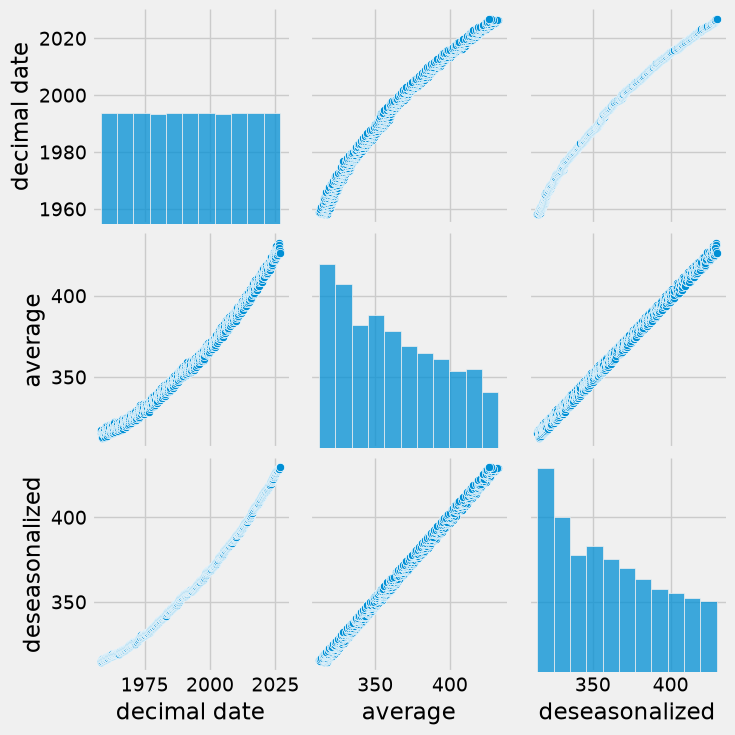

In [ ]:
'''

Pairplots are used to visualize relationships between numerical variables.
Each plot compares two variables, and the diagonal displays histograms.

'''

sns.pairplot(
    df,  
    vars=
    [
        "decimal date",
        "average",
        "deseasonalized",
    ]
)
plt.show()

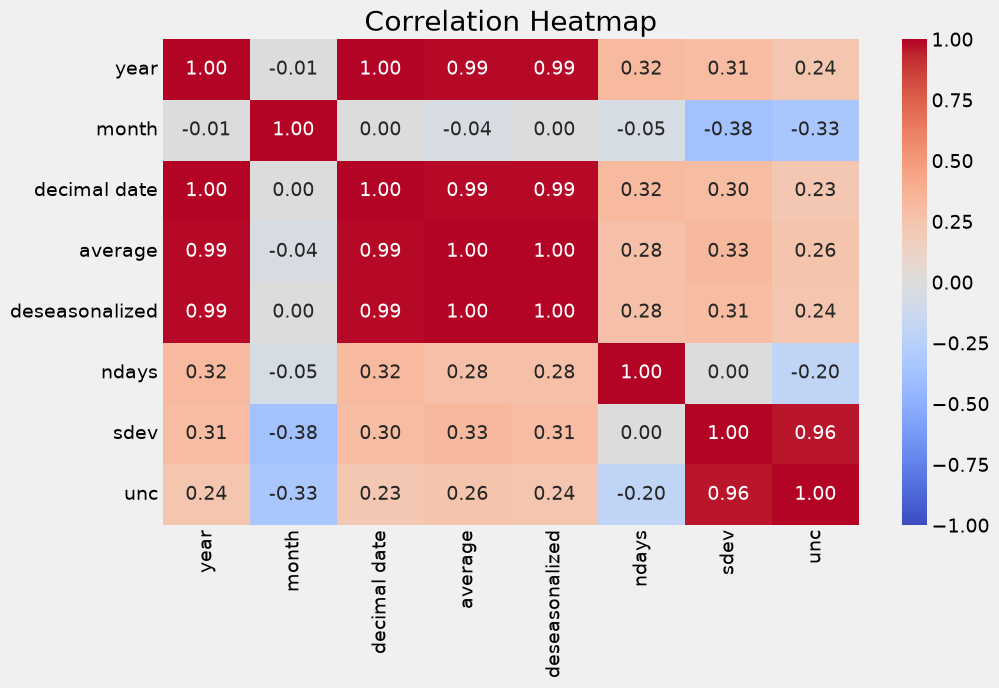

In [ ]:
'''
A correlation heatmap displays the relationships (correlations) between variables.
Values close to 1 or -1 indicate strong correlations.
Values close to 0 indicate weak or no correlations.               
'''

cols = ["ndays", "sdev", "unc"]
df[cols] = df[cols].mask(df[cols] < 0, np.nan)

correlation_matrix = df.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, center=0)
plt.title("Correlation Heatmap")
plt.show()


In [ ]:
df.head()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.71,314.44,NaN,NaN,NaN
1,1958,4,1958.2877,317.45,315.16,NaN,NaN,NaN
2,1958,5,1958.3699,317.51,314.69,NaN,NaN,NaN
3,1958,6,1958.4548,317.27,315.15,NaN,NaN,NaN
4,1958,7,1958.5370,315.87,315.20,NaN,NaN,NaN


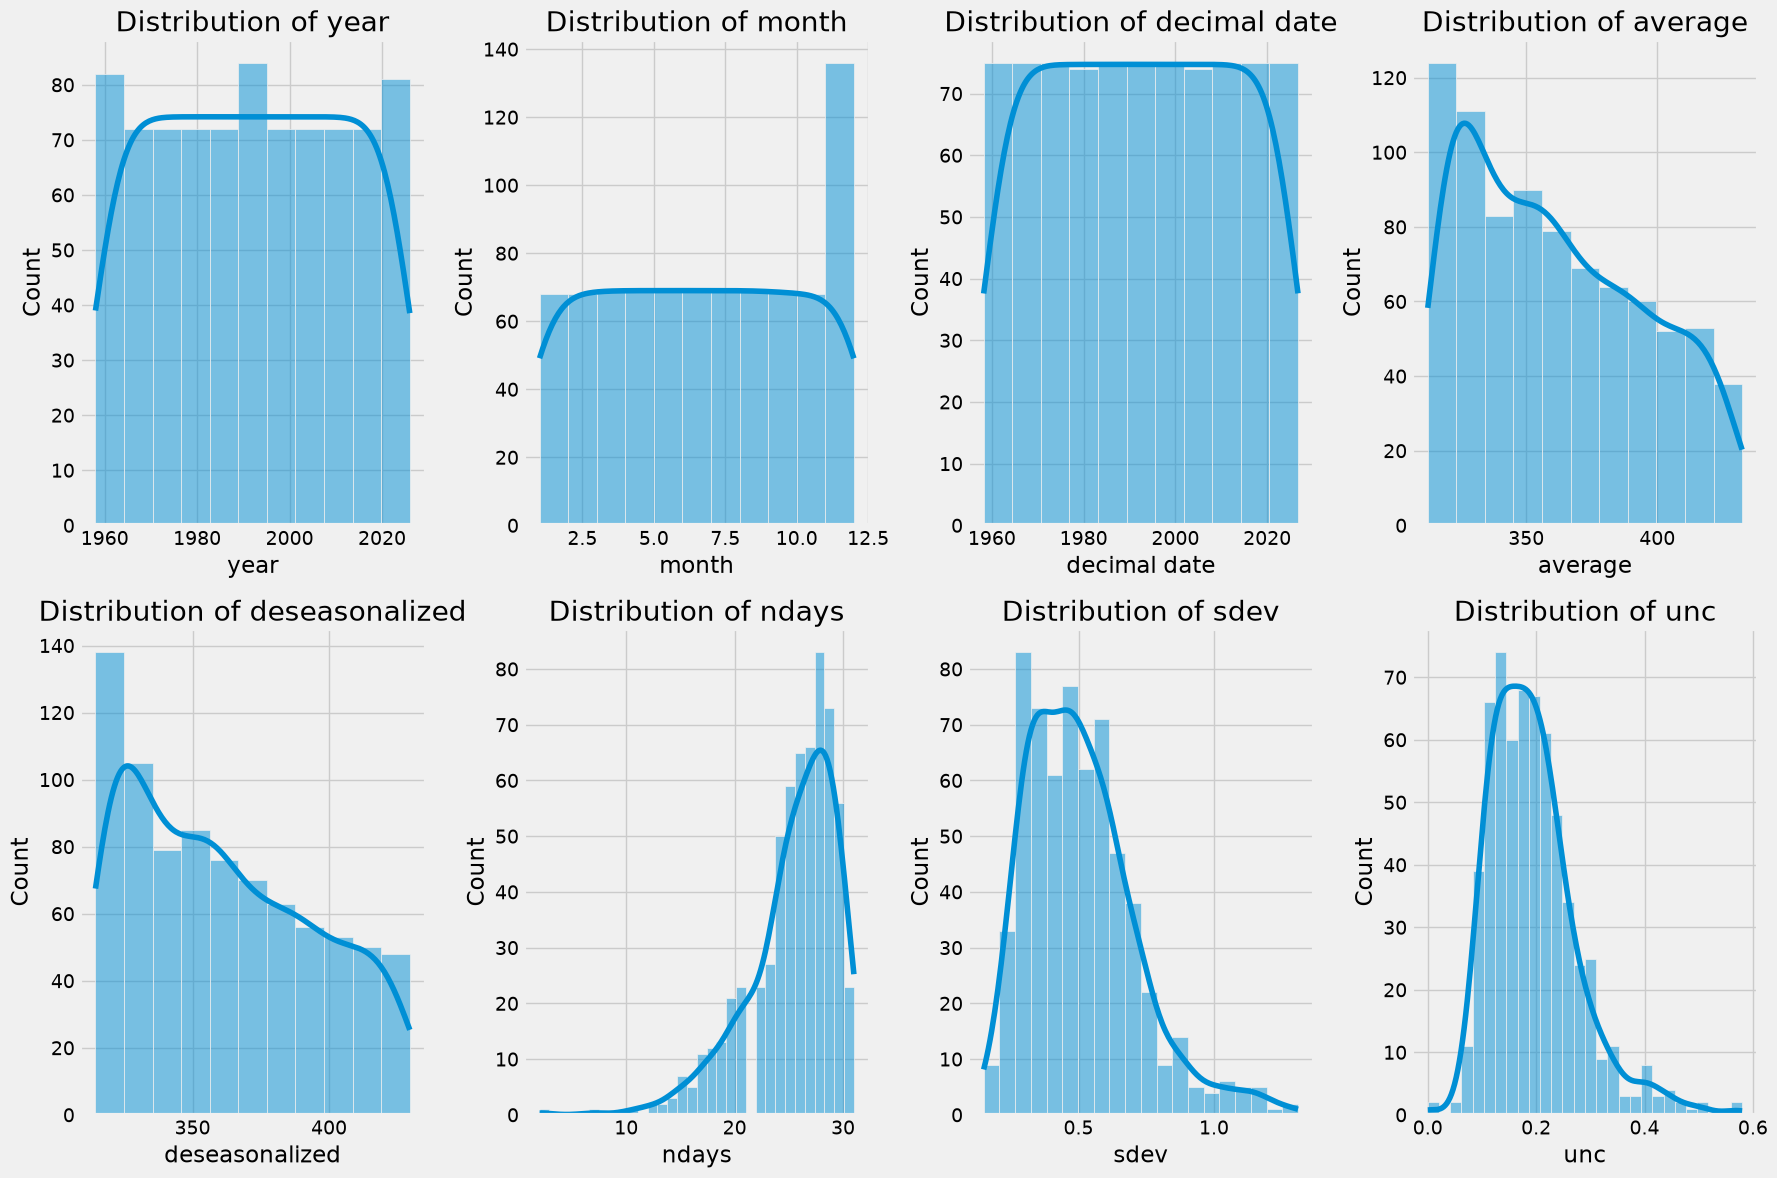

In [ ]:
'''
Data distribution plots, such as histograms, help visualize the distribution of individual numerical columns.
These plots can reveal the data's skewness and central tendencies.
'''
plt.figure(figsize=(18, 12))
numerical_columns = df.columns
for i, col in enumerate(numerical_columns):
    plt.subplot(2, 4, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

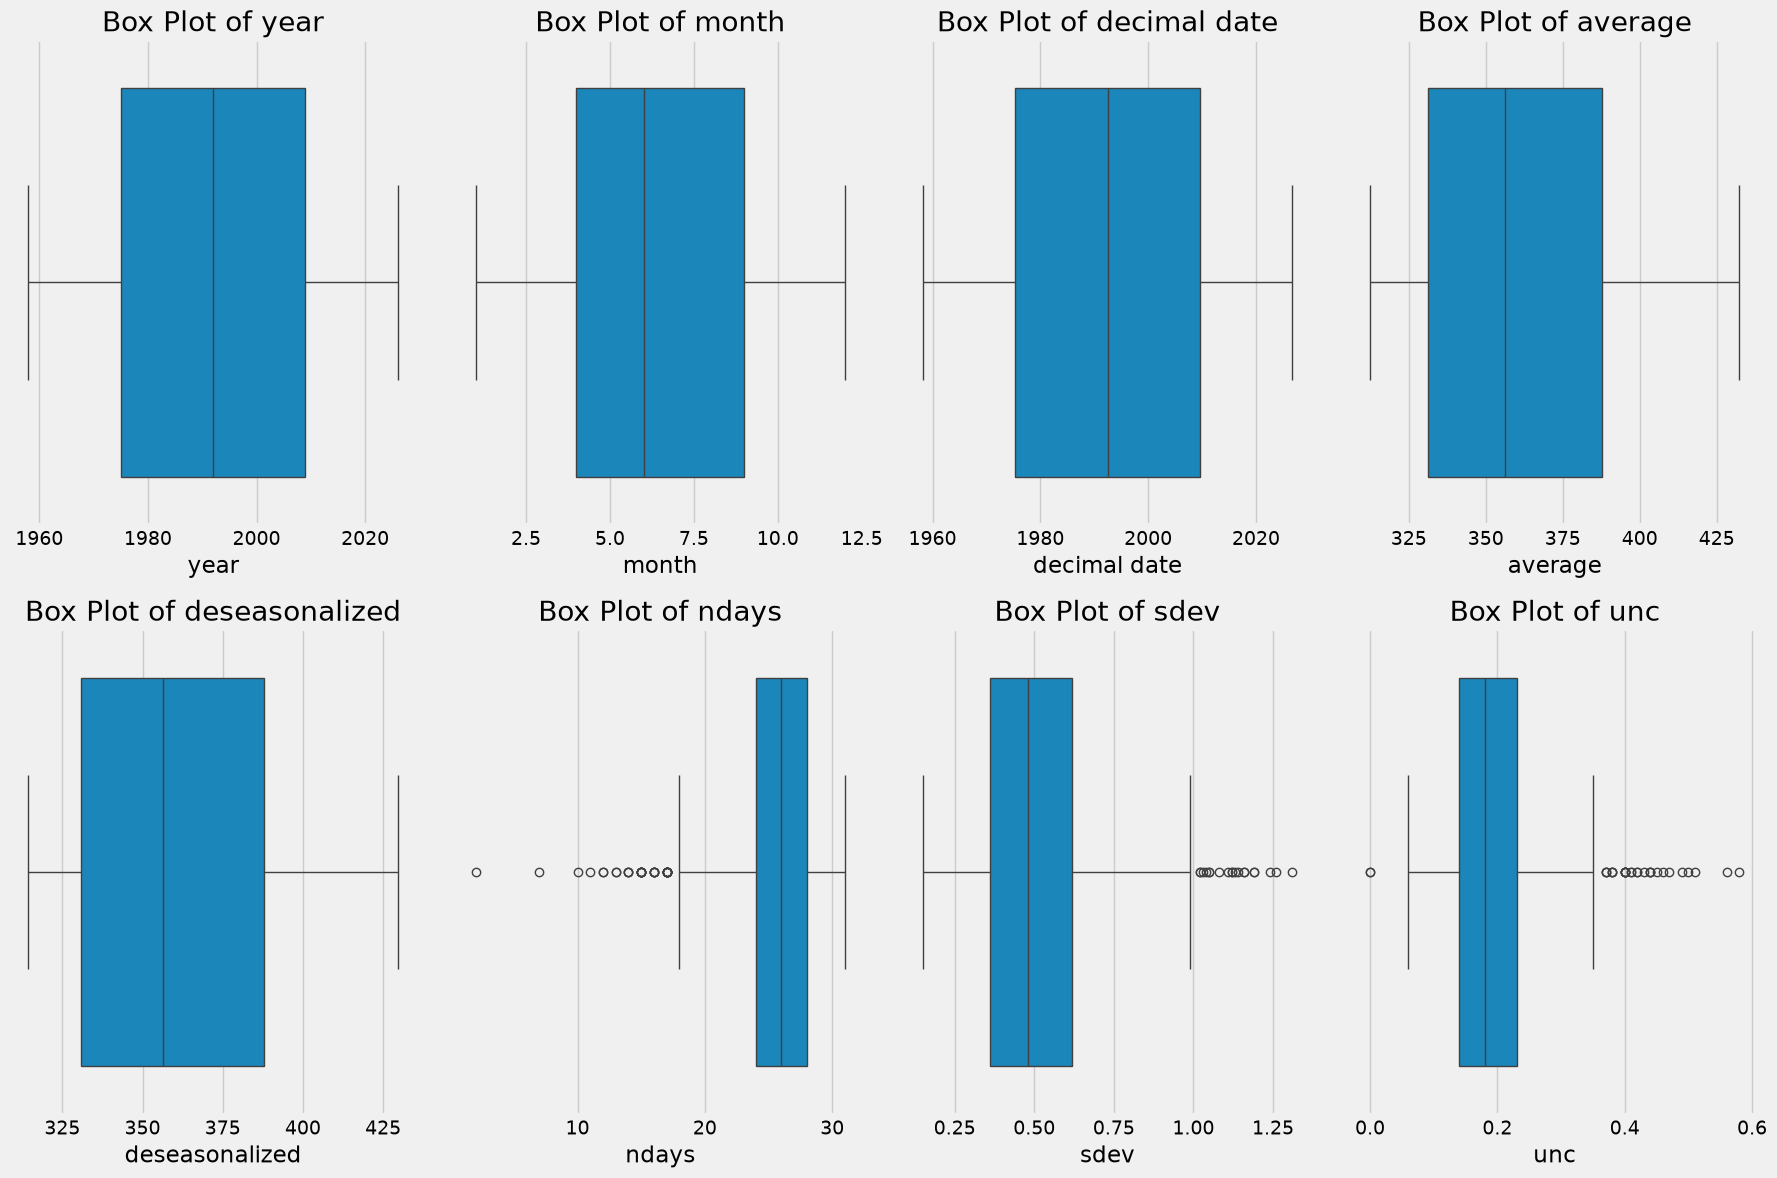

In [ ]:
# Box plots provide a way to visualize the spread and presence of outliers in numerical columns.

plt.figure(figsize=(18, 12))
for i, col in enumerate(numerical_columns):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(x=df[col])
    plt.title(f'Box Plot of {col}')
plt.tight_layout()
plt.show()